# Deliverable 1.2 - setup and initial exploration
**Current saved outputs: fabricated software fixture only.** These cells verify the loader and protocol logic; they do not establish real-data access, a post-43 drop, or trained-model performance.

After downloading the original three CSVs, set `DATA_MODE = "real"`, install the requirements, restart the kernel and Run All. Save the real outputs before submission.


In [1]:
from pathlib import Path
import sys, json, platform, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Launch from the project root or notebooks folder."
sys.path.insert(0, str(ROOT))
from src.data import load_elliptic, temporal_counts, summarize
from src.protocol import training_mask, recency_weights
from src.evaluate import classification_metrics
DATA_MODE = "sample"  # Change to "real" only after downloading original CSVs.
assert DATA_MODE in {"sample", "real"}
DATA_DIR = ROOT / "data" / ("raw" if DATA_MODE == "real" else "sample")
OUT = ROOT / "results" / DATA_MODE
OUT.mkdir(parents=True, exist_ok=True)
print("DATA MODE:", DATA_MODE.upper())
print("Python:", platform.python_version())
if DATA_MODE == "sample":
    print("FABRICATED FIXTURE ONLY - not empirical evidence.")


DATA MODE: SAMPLE
Python: 3.12.14
FABRICATED FIXTURE ONLY - not empirical evidence.


In [2]:
nodes, edges = load_elliptic(DATA_DIR)
summary = summarize(nodes, edges)
summary["data_mode"] = DATA_MODE
print(json.dumps(summary, indent=2))
print(nodes[["txId", "time_step", "class", "y"]].head().to_string(index=False))
if DATA_MODE == "real":
    assert len(nodes) == 203769 and len(edges) == 234355, "Unexpected release: investigate provenance."
    assert summary["label_counts"] == {"unknown": 157205, "2": 42019, "1": 4545}
(OUT / "data_summary.json").write_text(json.dumps(summary, indent=2))


{
  "nodes": 24,
  "edges": 20,
  "label_counts": {
    "2": 12,
    "unknown": 8,
    "1": 4
  },
  "validation_31_34_illicit": 1,
  "validation_31_34_licit": 3,
  "unlabeled_excluded_from_metrics": true,
  "data_mode": "sample"
}
 txId  time_step   class  y
  100          1       1  1
  101          1       2  0
  102          1       2  0
  103          1 unknown -1
  104          1 unknown -1


## Week-one check: observed counts and validation support
On original data, inspect illicit counts around step 43. Count changes alone do not establish predictive deterioration or its cause; execute the real frozen baseline next. Fixture plots below are visibly labeled and cannot satisfy the real-data check.


Validation support (steps 31-34):
           illicit  licit  unknown
time_step                         
31               1      3        2
32               0      0        0
33               0      0        0
34               0      0        0
Total validation illicit: 1


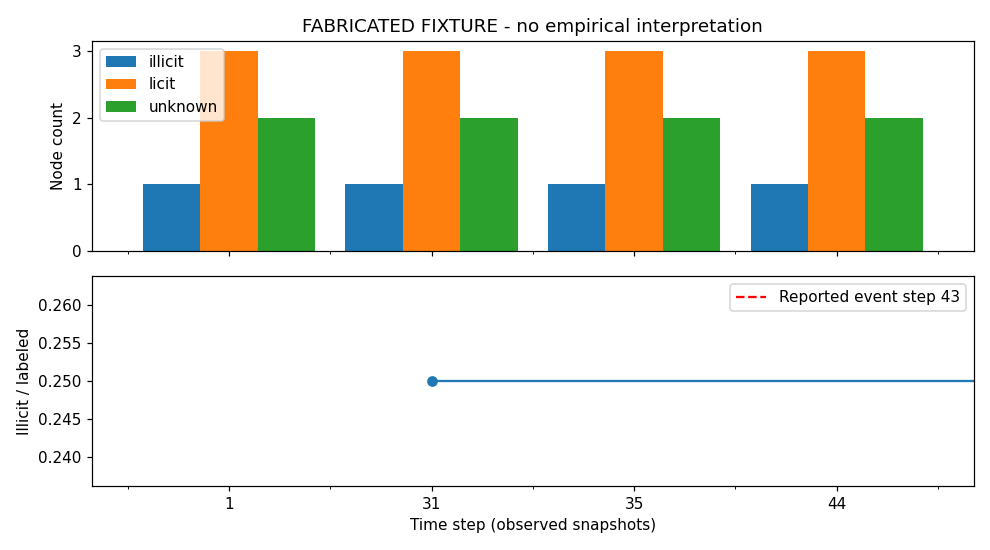

In [3]:
counts = temporal_counts(nodes)
counts.to_csv(OUT / "counts_by_step.csv")
print("Validation support (steps 31-34):")
print(counts.loc[31:34, ["illicit", "licit", "unknown"]].to_string())
print("Total validation illicit:", int(counts.loc[31:34, "illicit"].sum()))
observed = sorted(nodes.time_step.unique())
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
counts.loc[observed, ["illicit", "licit", "unknown"]].plot.bar(ax=axes[0], width=0.85)
axes[0].set_ylabel("Node count")
axes[0].set_title("Original Elliptic: observed label counts" if DATA_MODE == "real" else "FABRICATED FIXTURE - no empirical interpretation")
axes[1].plot(observed, counts.loc[observed, "illicit_share_labeled"], "o-")
axes[1].set_ylabel("Illicit / labeled")
axes[1].set_xlabel("Time step (observed snapshots)")
axes[1].axvline(43, color="red", linestyle="--", label="Reported event step 43")
axes[1].legend(loc="best")
fig.tight_layout()
fig.savefig(OUT / "label_counts.png", dpi=160)
plt.show()


In [4]:
# Meaningful protocol checks: unknown masking, future-label exclusion, recency ordering.
t = np.array([1, 30, 31, 34, 35, 36])
y = np.array([0, 1, -1, 1, 0, 1])
assert training_mask(t, y, 35, "frozen").tolist() == [True, True, False, False, False, False]
assert training_mask(t, y, 35, "rolling", window=4).tolist() == [False, False, False, True, False, False]
assert not training_mask(t, y, 35, "expanding")[t >= 35].any()
w = recency_weights([30, 34], 35, half_life=4)
assert np.isclose(w[0], 0.5) and np.isclose(w[1], 1.0)
a = classification_metrics(np.array([1, 0, -1]), np.array([0.8, 0.2, 0.99]))
b = classification_metrics(np.array([1, 0, -1]), np.array([0.8, 0.2, 0.01]))
assert a == b, "Unknown-node scores must not affect labeled metrics."
print("PASS: temporal policies, unknown-label masking, recency weights and metric isolation.")


PASS: temporal policies, unknown-label masking, recency weights and metric isolation.


In [5]:
# Full-stack checks are separate from the data/EDA checks above.
packages = ["torch", "torch_geometric", "xgboost", "streamlit"]
missing = [name for name in packages if importlib.util.find_spec(name) is None]
if missing:
    print("FULL MODEL/UI ENVIRONMENT INCOMPLETE:", ", ".join(missing))
    print("Install requirements.txt and rerun before claiming full environment readiness.")
else:
    import torch, torch_geometric, xgboost, streamlit
    from src.models import MLP, GraphSAGE
    x = torch.randn(4, 93)
    edge_index = torch.tensor([[0, 1, 2], [1, 2, 3]], dtype=torch.long)
    for model in [MLP(), GraphSAGE()]:
        output = model(x, edge_index)
        assert output.shape == (4,) and torch.isfinite(output).all()
    print("PASS: core model forward passes; torch", torch.__version__, "PyG", torch_geometric.__version__)
    print("CUDA available:", torch.cuda.is_available())
if DATA_MODE == "real":
    assert not missing, "Full environment verification is required for the real-data submission."


FULL MODEL/UI ENVIRONMENT INCOMPLETE: torch, torch_geometric, xgboost, streamlit
Install requirements.txt and rerun before claiming full environment readiness.


## Next required execution
1. Run `python -m src.baseline --data-dir data/raw --output-dir results/real` from the repository root.
2. Inspect `results/real/baseline_by_step.csv` and plot F1/AP with illicit support before/after step 43. A drop is a hypothesis to check, not guaranteed output.
3. Retain all runs, including unexpected findings. Commit this notebook with original-data outputs and update README status.
4. Implement the common trainer and prequential adaptation loop; `src/models.py` provides initial architecture definitions, not a completed robustness experiment.
